# Домашнее задание: Matplotlib (10 заданий)

**Задача:** применить Matplotlib к заказам интернет-магазина. Все графики строятся **на одном файле `orders_2025.csv`**.

- Сдать заполненный notebook `.ipynb` и (по желанию) сохраненный итоговый рисунок `.png`.
- На каждом графике: осмысленный заголовок, подписанные оси, единицы измерения; легенда — если несколько рядов.
- После каждого задания напишите 1–2 предложения **какой факт показывает диаграмма и почему выбран такой тип**.
- `revenue` — сумма заказа после скидки, но до обработки возвратов. `discount_pct` — доля, умножьте на 100 для процентов.
- Данные синтетические; не делайте выводов о реальных магазинах.

**Оценивание:** 10 баллов, по 1 баллу за задание: 0.4 обработка данных, 0.4 корректный график, 0.2 оформление и вывод.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.alpha": 0.18
})

path = Path("orders_2025.csv")
df = pd.read_csv(path, parse_dates=["order_date"])
df.head()


,order_id,order_date,region,category,channel,customer_segment,units,unit_price,discount_pct,revenue,delivery_days,rating,returned
0,ORD-2025-00001,2025-01-01,Центр,Дом,Приложение,VIP,4,3810.0,0.165,12725.4,2.0,NaN,0
1,ORD-2025-00002,2025-01-01,Урал,Одежда,Приложение,Постоянный,2,5210.0,0.020,10211.6,5.0,5.0,0
2,ORD-2025-00003,2025-01-01,Центр,Дом,Приложение,Постоянный,1,4840.0,0.150,4114.0,1.0,5.0,0
3,ORD-2025-00004,2025-01-01,Сибирь,Электроника,Приложение,Новый,2,8380.0,0.120,14748.8,6.0,5.0,0
4,ORD-2025-00005,2025-01-01,Сибирь,Книги,Приложение,Новый,3,650.0,0.060,1833.0,16.0,3.0,0


## Задание 1. Количество заказов по месяцам

Постройте bar-график **количества** заказов по месяцам. Не путайте количество с суммой выручки. Выделите максимальный месяц и укажите численное значение.

*Подсказка:* `groupby/resample + size()`

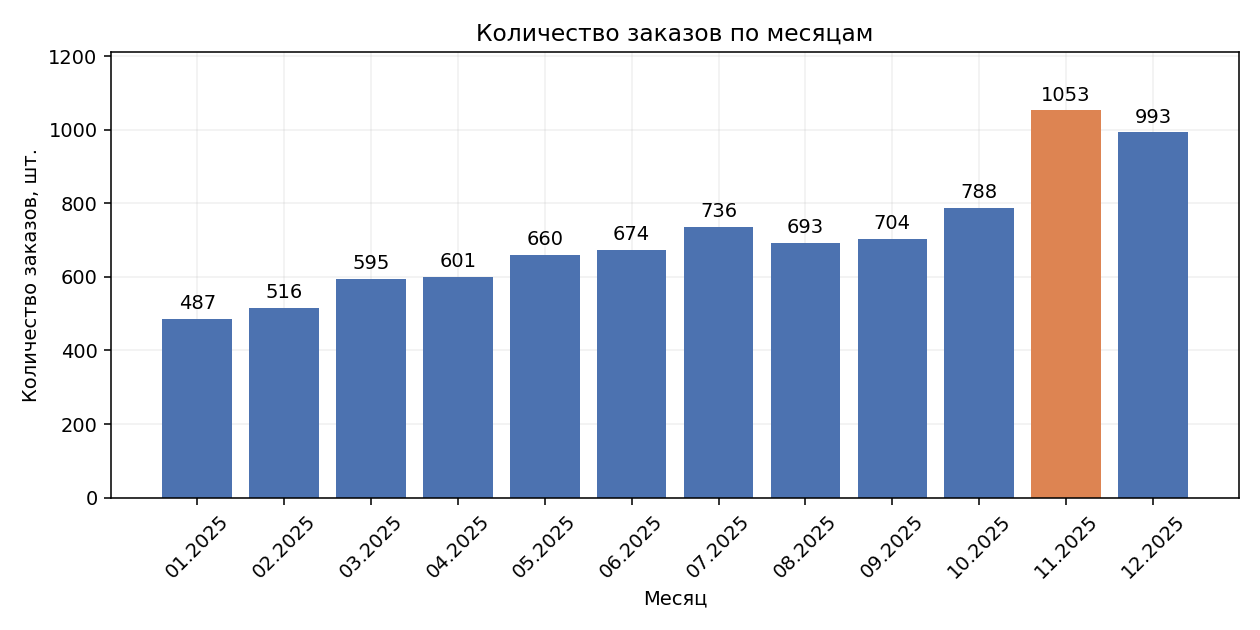

In [2]:
monthly_orders = df.set_index("order_date").resample("MS").size()
colors = ["#DD8452" if value == monthly_orders.max() else "#4C72B0"
          for value in monthly_orders]

fig, ax = plt.subplots()
bars = ax.bar(monthly_orders.index.strftime("%m.%Y"), monthly_orders, color=colors)
ax.bar_label(bars, padding=3)
ax.set_title("Количество заказов по месяцам")
ax.set_xlabel("Месяц")
ax.set_ylabel("Количество заказов, шт.")
ax.set_ylim(0, monthly_orders.max() * 1.15)
ax.tick_params(axis="x", rotation=45)
fig.tight_layout()
plt.show()


Максимум заказов в ноябре — 1053; месяц выделен оранжевым.
Столбцы позволяют точно сравнить количество заказов в разные месяцы.


## Задание 2. Выручка по неделям

Постройте недельную выручку линией. Добавьте сетку, подписи осей и отметьте максимальную неделю аннотацией.

*Подсказка:* `resample("W")`

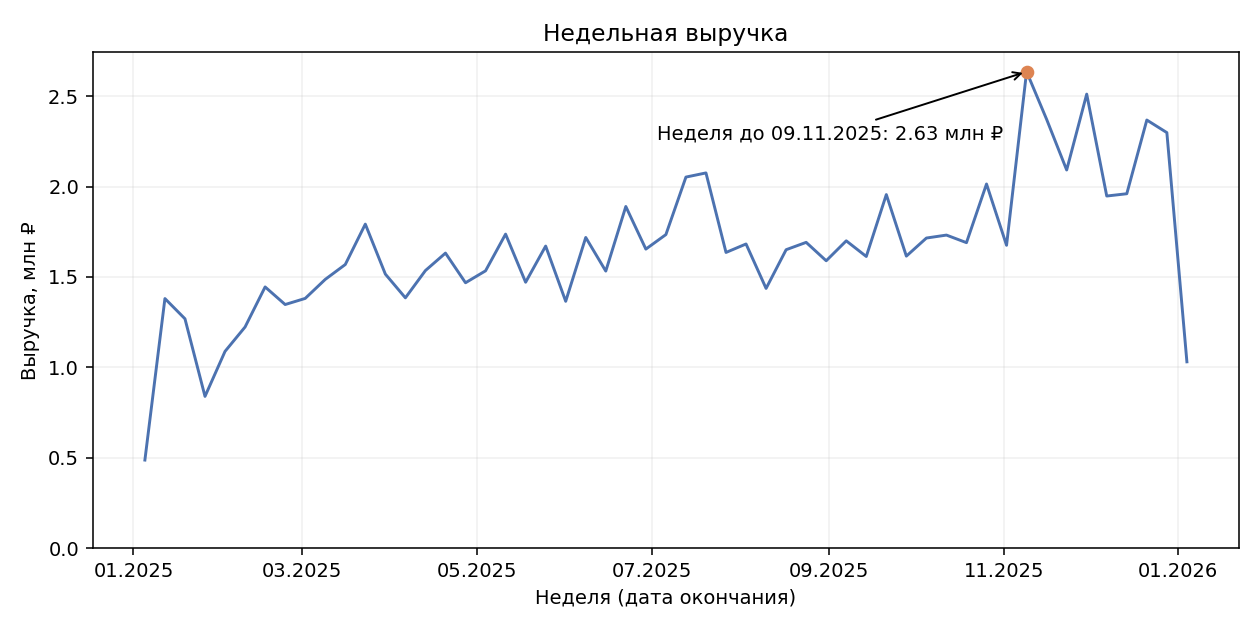

In [3]:
weekly_revenue = df.set_index("order_date")["revenue"].resample("W").sum() / 1_000_000
peak_week = weekly_revenue.idxmax()
peak_revenue = weekly_revenue.max()

fig, ax = plt.subplots()
ax.plot(weekly_revenue.index, weekly_revenue, color="#4C72B0")
ax.scatter(peak_week, peak_revenue, color="#DD8452", zorder=3)
ax.annotate(
    f"Неделя до {peak_week:%d.%m.%Y}: {peak_revenue:.2f} млн ₽",
    xy=(peak_week, peak_revenue), xytext=(-190, -35),
    textcoords="offset points", arrowprops={"arrowstyle": "->"}
)
ax.set_title("Недельная выручка")
ax.set_xlabel("Неделя (дата окончания)")
ax.set_ylabel("Выручка, млн ₽")
ax.set_ylim(bottom=0)
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m.%Y"))
ax.grid(True)
fig.tight_layout()
plt.show()


Максимальная недельная выручка — 2,63 млн ₽ за 3–9 ноября 2025 года;
линия показывает её изменение во времени. Первая и последняя недели содержат
только дни, попавшие в 2025 год, поэтому их значения не полностью сопоставимы с полными неделями.


## Задание 3. Каналы: абсолютные величины и доли

Постройте **два** графика: bar количества заказов по каналам и pie/donut долей. В одной фразе объясните, какой проще для точного сравнения.

*Подсказка:* `value_counts(), pie()`

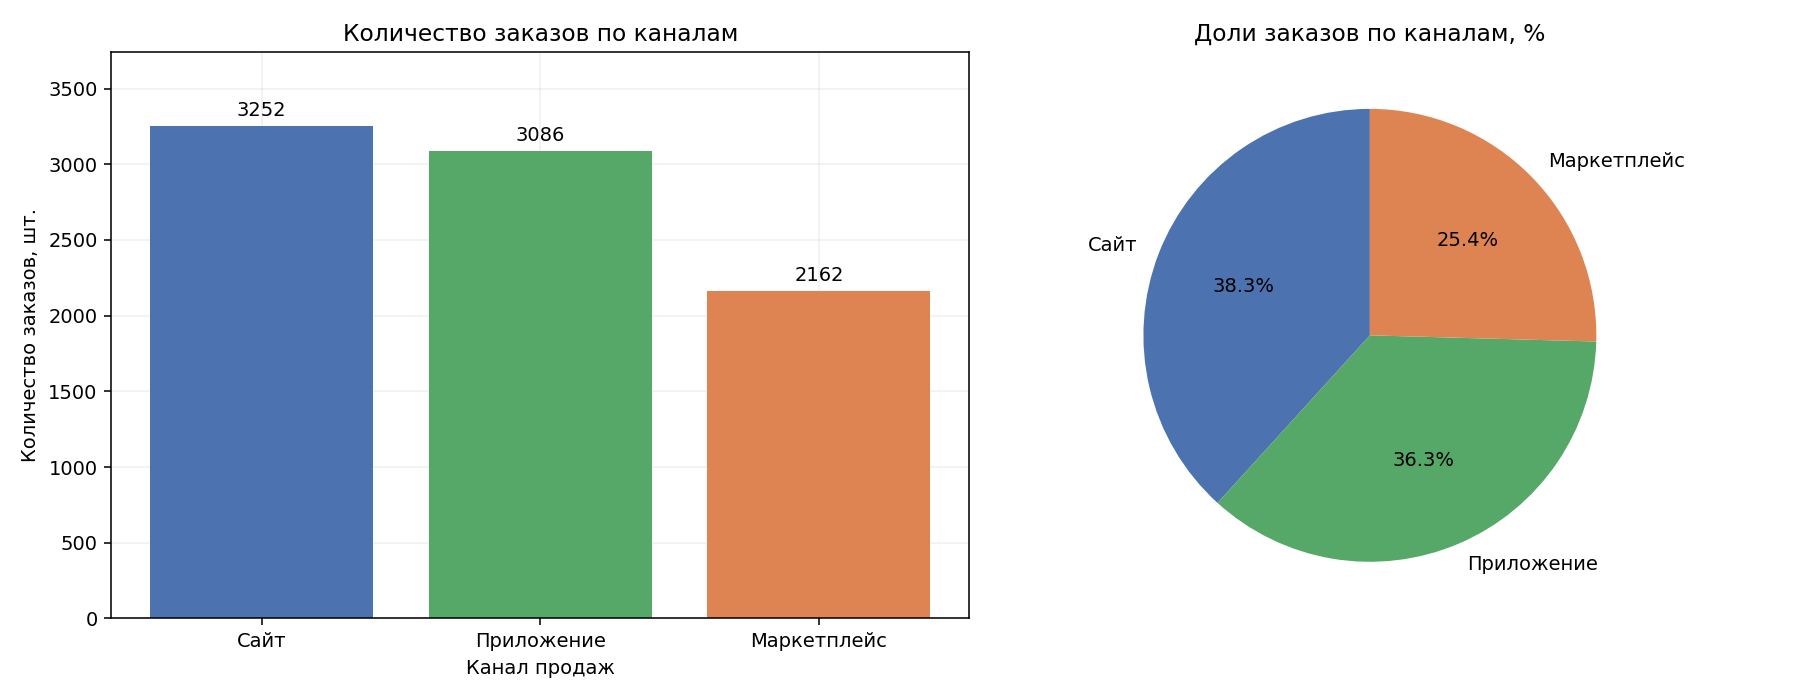

In [4]:
channel_orders = df["channel"].value_counts()
colors = ["#4C72B0", "#55A868", "#DD8452"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
bars = axes[0].bar(channel_orders.index, channel_orders, color=colors)
axes[0].bar_label(bars, padding=3)
axes[0].set_title("Количество заказов по каналам")
axes[0].set_xlabel("Канал продаж")
axes[0].set_ylabel("Количество заказов, шт.")
axes[0].set_ylim(0, channel_orders.max() * 1.15)

axes[1].pie(channel_orders, labels=channel_orders.index,
            autopct="%.1f%%", startangle=90, colors=colors)
axes[1].set_title("Доли заказов по каналам, %")
fig.tight_layout()
plt.show()


Сайт даёт 3252 заказа (38,3%), приложение — 3086 (36,3%),
маркетплейс — 2162 (25,4%). Круговая диаграмма показывает состав целого,
а столбцы удобнее для точного сравнения близких значений.


## Задание 4. Средний чек и суммарная выручка

Для каждой категории покажите средний чек и суммарную выручку на **двух отдельных** горизонтальных bar-графиках. Сравните рейтинги.

*Подсказка:* `agg(mean, sum), barh()`

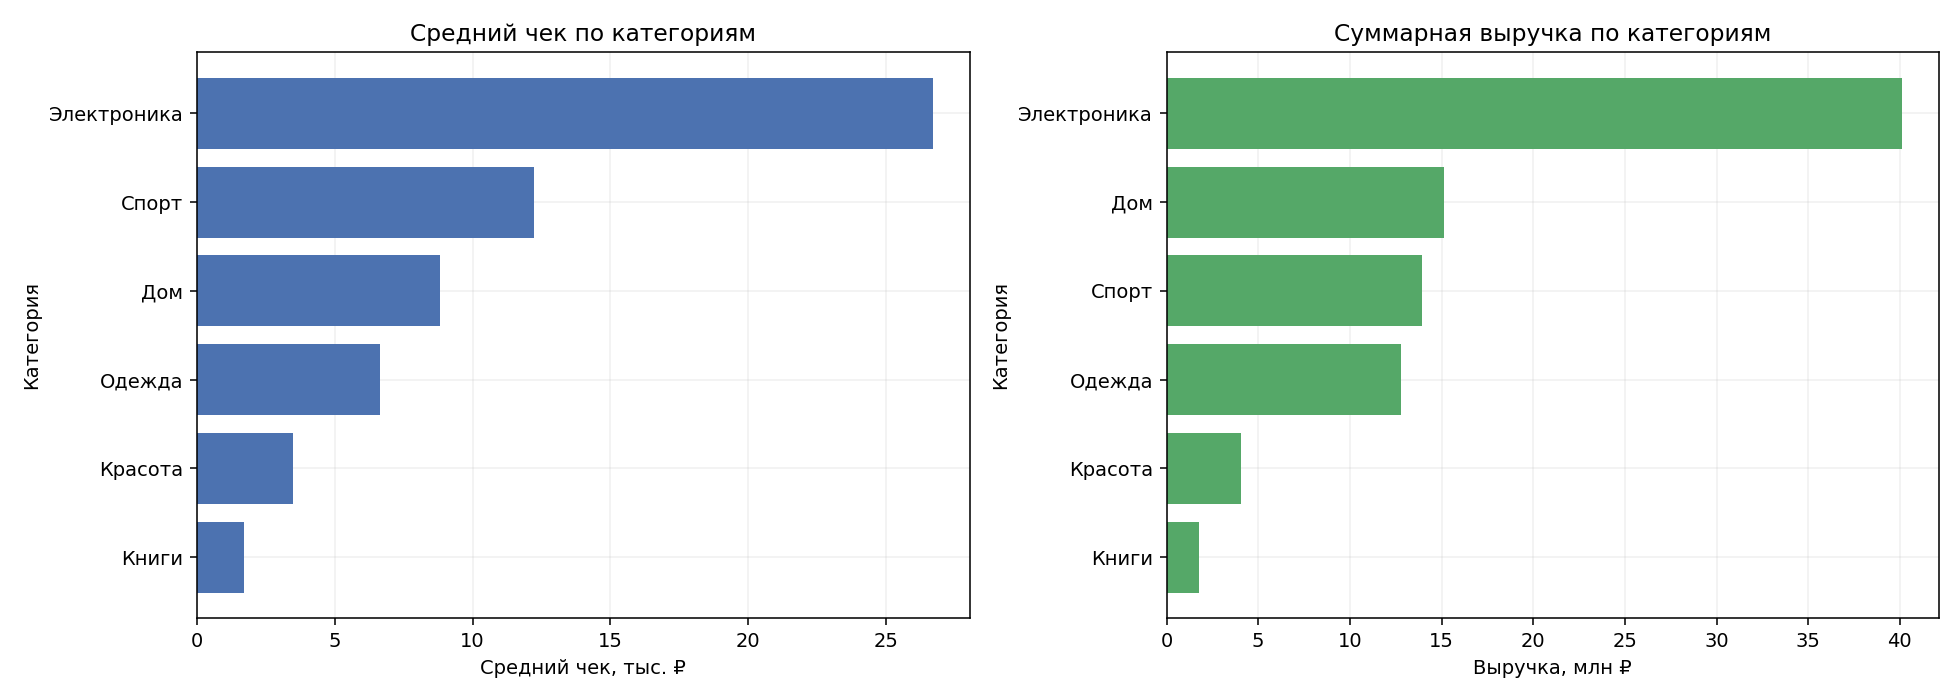

In [5]:
category_stats = df.groupby("category")["revenue"].agg(["mean", "sum"])
mean_check = category_stats["mean"].sort_values() / 1_000
category_revenue = category_stats["sum"].sort_values() / 1_000_000

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(mean_check.index, mean_check, color="#4C72B0")
axes[0].set_title("Средний чек по категориям")
axes[0].set_xlabel("Средний чек, тыс. ₽")
axes[0].set_ylabel("Категория")

axes[1].barh(category_revenue.index, category_revenue, color="#55A868")
axes[1].set_title("Суммарная выручка по категориям")
axes[1].set_xlabel("Выручка, млн ₽")
axes[1].set_ylabel("Категория")
fig.tight_layout()
plt.show()


Электроника лидирует и по среднему чеку (26,70 тыс. ₽), и по выручке
(40,13 млн ₽), но второе место по чеку занимает спорт, а по выручке — дом.
Горизонтальные столбцы удобны для сравнения рейтингов и длинных названий категорий.


## Задание 5. Скидки: форма распределения

Постройте гистограммы скидки в процентах с bins=10 и bins=35. Оцените, как меняется вид. Укажите медиану скидки вертикальной линией.

*Подсказка:* `hist(), axvline()`

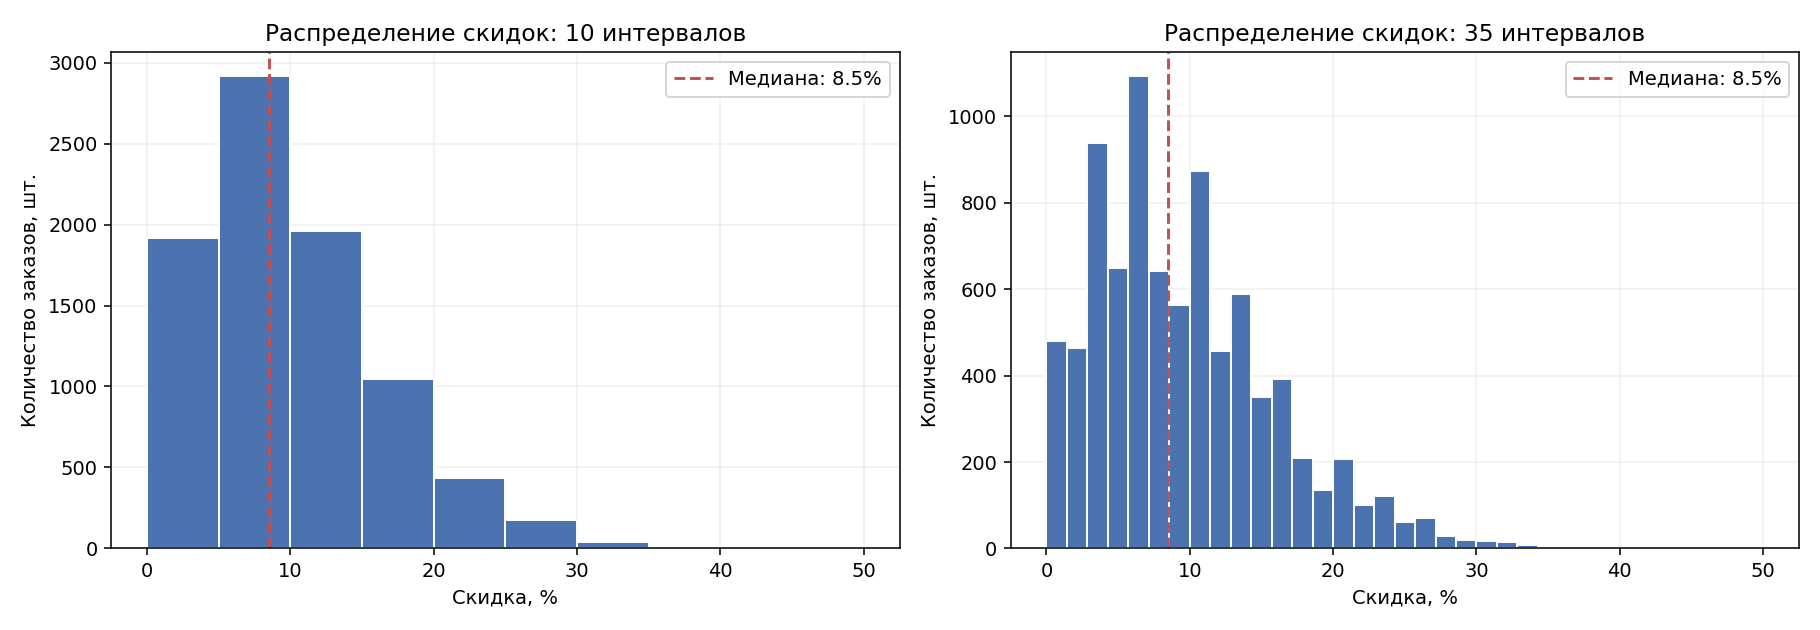

In [6]:
discounts = df["discount_pct"] * 100
median_discount = discounts.median()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True)
for ax, bins in zip(axes, [10, 35]):
    ax.hist(discounts, bins=bins, range=(0, 50),
            color="#4C72B0", edgecolor="white")
    ax.axvline(median_discount, color="#C44E52", linestyle="--",
               label=f"Медиана: {median_discount:.1f}%")
    ax.set_title(f"Распределение скидок: {bins} интервалов")
    ax.set_xlabel("Скидка, %")
    ax.set_ylabel("Количество заказов, шт.")
    ax.legend()
fig.tight_layout()
plt.show()


Распределение скидок имеет правый хвост, медиана равна 8,5%.
Гистограмма с 10 интервалами показывает общую форму, с 35 — больше деталей
и неровностей, связанных в том числе с округлением скидок.


## Задание 6. Boxplot доставки по регионам

Сравните сроки доставки между регионами: boxplot; пропуски удаляйте только в `delivery_days`. Охарактеризуйте медиану и выбросы.

*Подсказка:* `dropna(), boxplot()`

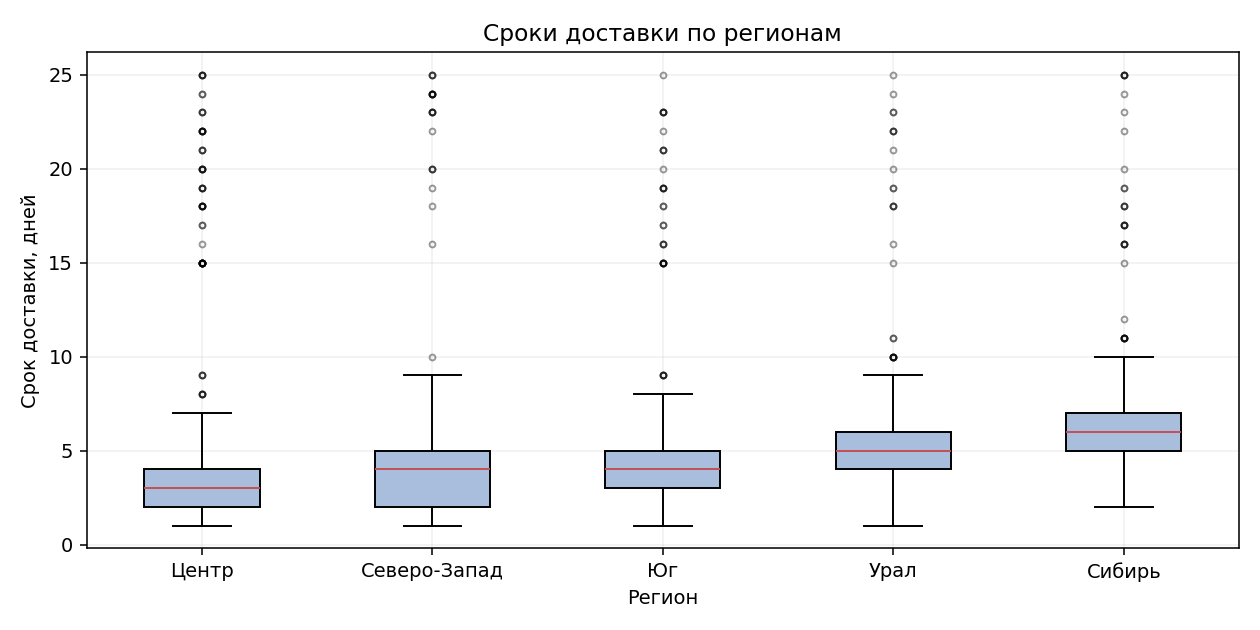

In [7]:
delivery = df.dropna(subset=["delivery_days"])
regions = delivery.groupby("region")["delivery_days"].median().sort_values().index
delivery_groups = [delivery.loc[delivery["region"] == region, "delivery_days"]
                   for region in regions]

fig, ax = plt.subplots()
ax.boxplot(delivery_groups, patch_artist=True,
           boxprops={"facecolor": "#A9BEDD"},
           medianprops={"color": "#C44E52"},
           flierprops={"marker": ".", "alpha": 0.4})
ax.set_xticks(range(1, len(regions) + 1), regions)
ax.set_title("Сроки доставки по регионам")
ax.set_xlabel("Регион")
ax.set_ylabel("Срок доставки, дней")
fig.tight_layout()
plt.show()


Медиана доставки минимальна в Центре — 3 дня, максимальна в Сибири —
6 дней; встречаются выбросы вплоть до 25 дней. Boxplot сравнивает медианы,
разброс и выбросы; исключены только 277 строк с неизвестным сроком доставки,
пропуски рейтинга не влияют на отбор.


## Задание 7. Scatter: цена и итоговый чек

Покажите связь цены единицы товара и суммы заказа (случайная выборка не более 1500 строк), используйте alpha. Почему сильная связь не является неожиданной?

*Подсказка:* `sample(), scatter()`

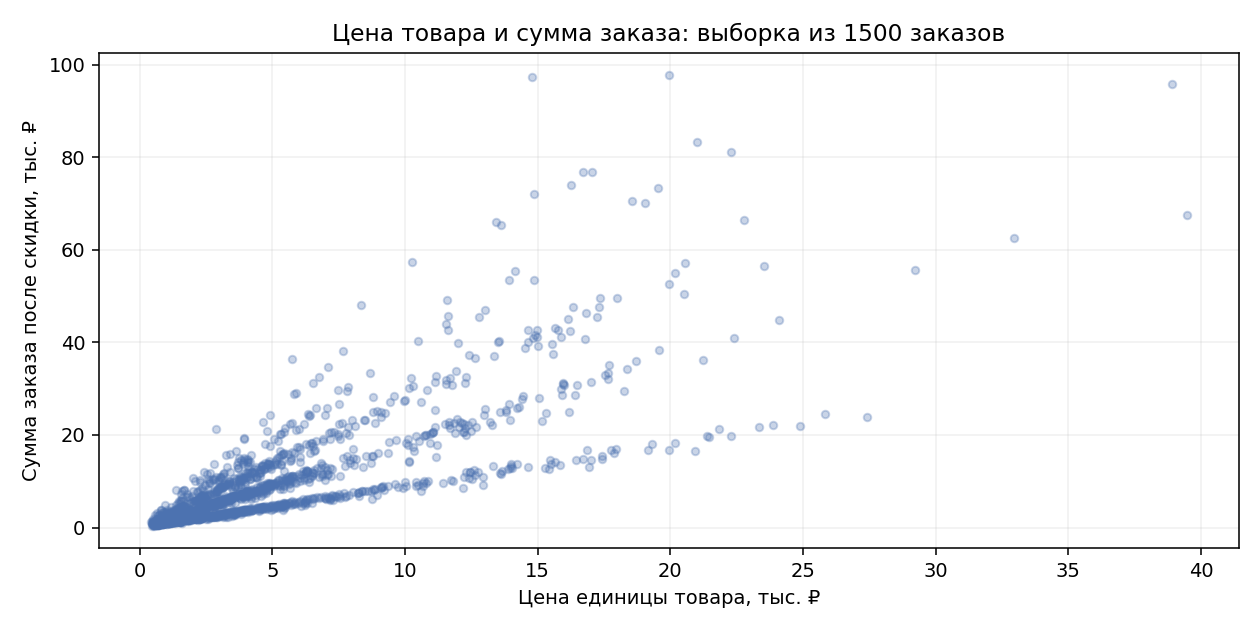

In [8]:
price_sample = df.sample(n=min(1500, len(df)), random_state=42)

fig, ax = plt.subplots()
ax.scatter(price_sample["unit_price"] / 1_000, price_sample["revenue"] / 1_000,
           alpha=0.3, s=15, color="#4C72B0")
ax.set_title("Цена товара и сумма заказа: выборка из 1500 заказов")
ax.set_xlabel("Цена единицы товара, тыс. ₽")
ax.set_ylabel("Сумма заказа после скидки, тыс. ₽")
fig.tight_layout()
plt.show()


На диаграмме рассеяния более высокая цена товара обычно соответствует
большей сумме заказа, при этом виден разброс значений. Сильная связь ожидаема:
сумма заказа рассчитывается как `units × unit_price × (1 − discount_pct)`.


## Задание 8. 100%-накопленные столбцы по сегментам

Сравните доли **каналов продаж** в сегментах Новый/Постоянный/VIP с помощью 100% stacked bar. Убедитесь, что каждый столбец составляет 100%.

*Подсказка:* `crosstab(normalize="index")`

Сумма долей в каждом сегменте, %:
customer_segment
Новый         100.0
Постоянный    100.0
VIP           100.0
dtype: float64


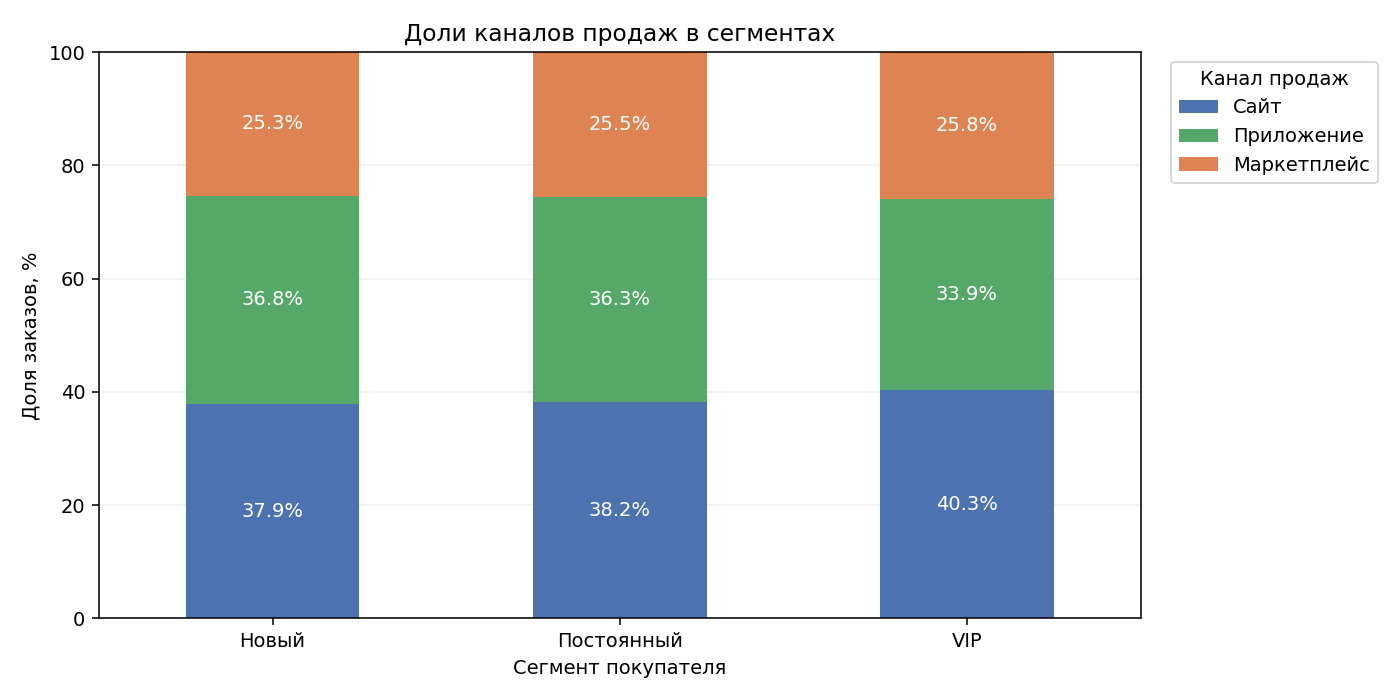

In [9]:
channel_shares = pd.crosstab(df["customer_segment"], df["channel"], normalize="index")
channel_shares = channel_shares.reindex(
    index=["Новый", "Постоянный", "VIP"],
    columns=["Сайт", "Приложение", "Маркетплейс"]
) * 100
print("Сумма долей в каждом сегменте, %:")
print(channel_shares.sum(axis=1).round(6))

fig, ax = plt.subplots(figsize=(10, 5))
channel_shares.plot(kind="bar", stacked=True, ax=ax, rot=0,
                    color=["#4C72B0", "#55A868", "#DD8452"])
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.1f%%", label_type="center", color="white")
ax.set_title("Доли каналов продаж в сегментах")
ax.set_xlabel("Сегмент покупателя")
ax.set_ylabel("Доля заказов, %")
ax.set_ylim(0, 100)
ax.legend(title="Канал продаж", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
plt.show()


Во всех сегментах на сайт приходится около 38–40% заказов,
на маркетплейс — около 25–26%; в каждом столбце сумма долей равна 100%.
Накопленные столбцы позволяют сравнить структуру каналов при разном числе
заказов в сегментах.


## Задание 9. Тепловая карта выручки

Создайте heatmap: строки — месяцы, колонки — категории, значение — сумма выручки в млн ₽. Добавьте colorbar, подписи и название.

*Подсказка:* `pivot_table, imshow()`

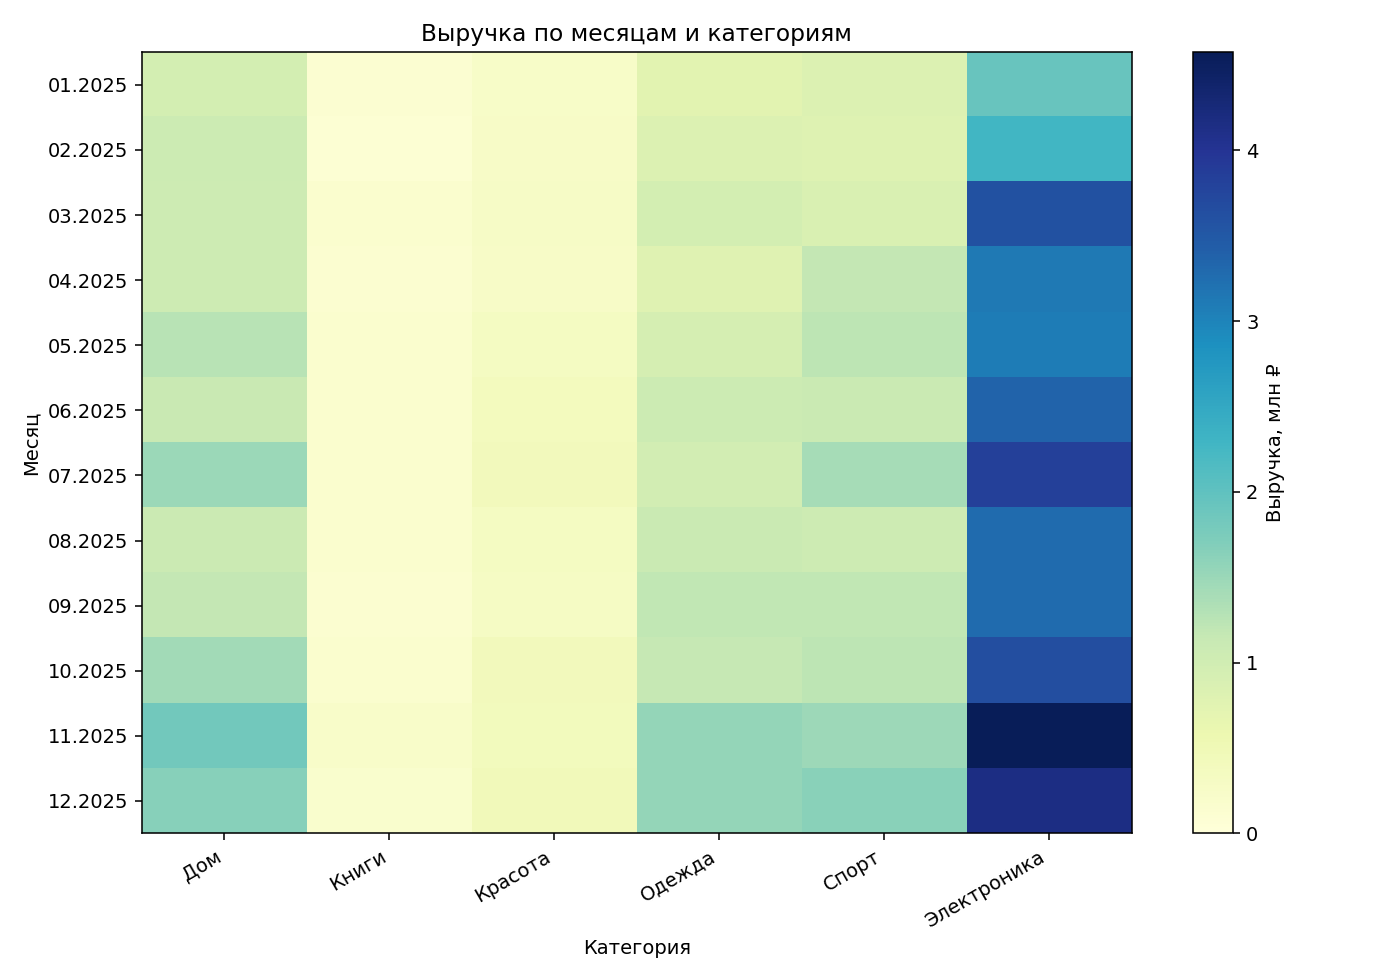

In [10]:
revenue_heatmap = df.pivot_table(
    index=df["order_date"].dt.to_period("M"), columns="category",
    values="revenue", aggfunc="sum", fill_value=0
) / 1_000_000

fig, ax = plt.subplots(figsize=(10, 7))
image = ax.imshow(revenue_heatmap, aspect="auto", cmap="YlGnBu", vmin=0)
ax.set_xticks(range(len(revenue_heatmap.columns)), revenue_heatmap.columns,
              rotation=30, ha="right")
ax.set_yticks(range(len(revenue_heatmap.index)),
              revenue_heatmap.index.strftime("%m.%Y"))
ax.set_title("Выручка по месяцам и категориям")
ax.set_xlabel("Категория")
ax.set_ylabel("Месяц")
ax.grid(False)
fig.colorbar(image, ax=ax, label="Выручка, млн ₽")
fig.tight_layout()
plt.show()


Самая большая выручка в одной ячейке — электроника в ноябре,
4,58 млн ₽; электроника лидирует во всех месяцах. Тепловая карта позволяет
одновременно сравнить категории и месяцы по цвету, а шкала показывает суммы в млн ₽.


## Задание 10. Аналитический dashboard

Создайте фигуру 2×2: (1) недельная выручка — line; (2) выручка категорий — barh; (3) распределение чеков — hist; (4) **доля возвратов по регионам** — bar. После графиков напишите 3 проверяемых вывода и одну оговорку об ограничениях данных.

*Подсказка:* `plt.subplots(2,2), groupby/agg`

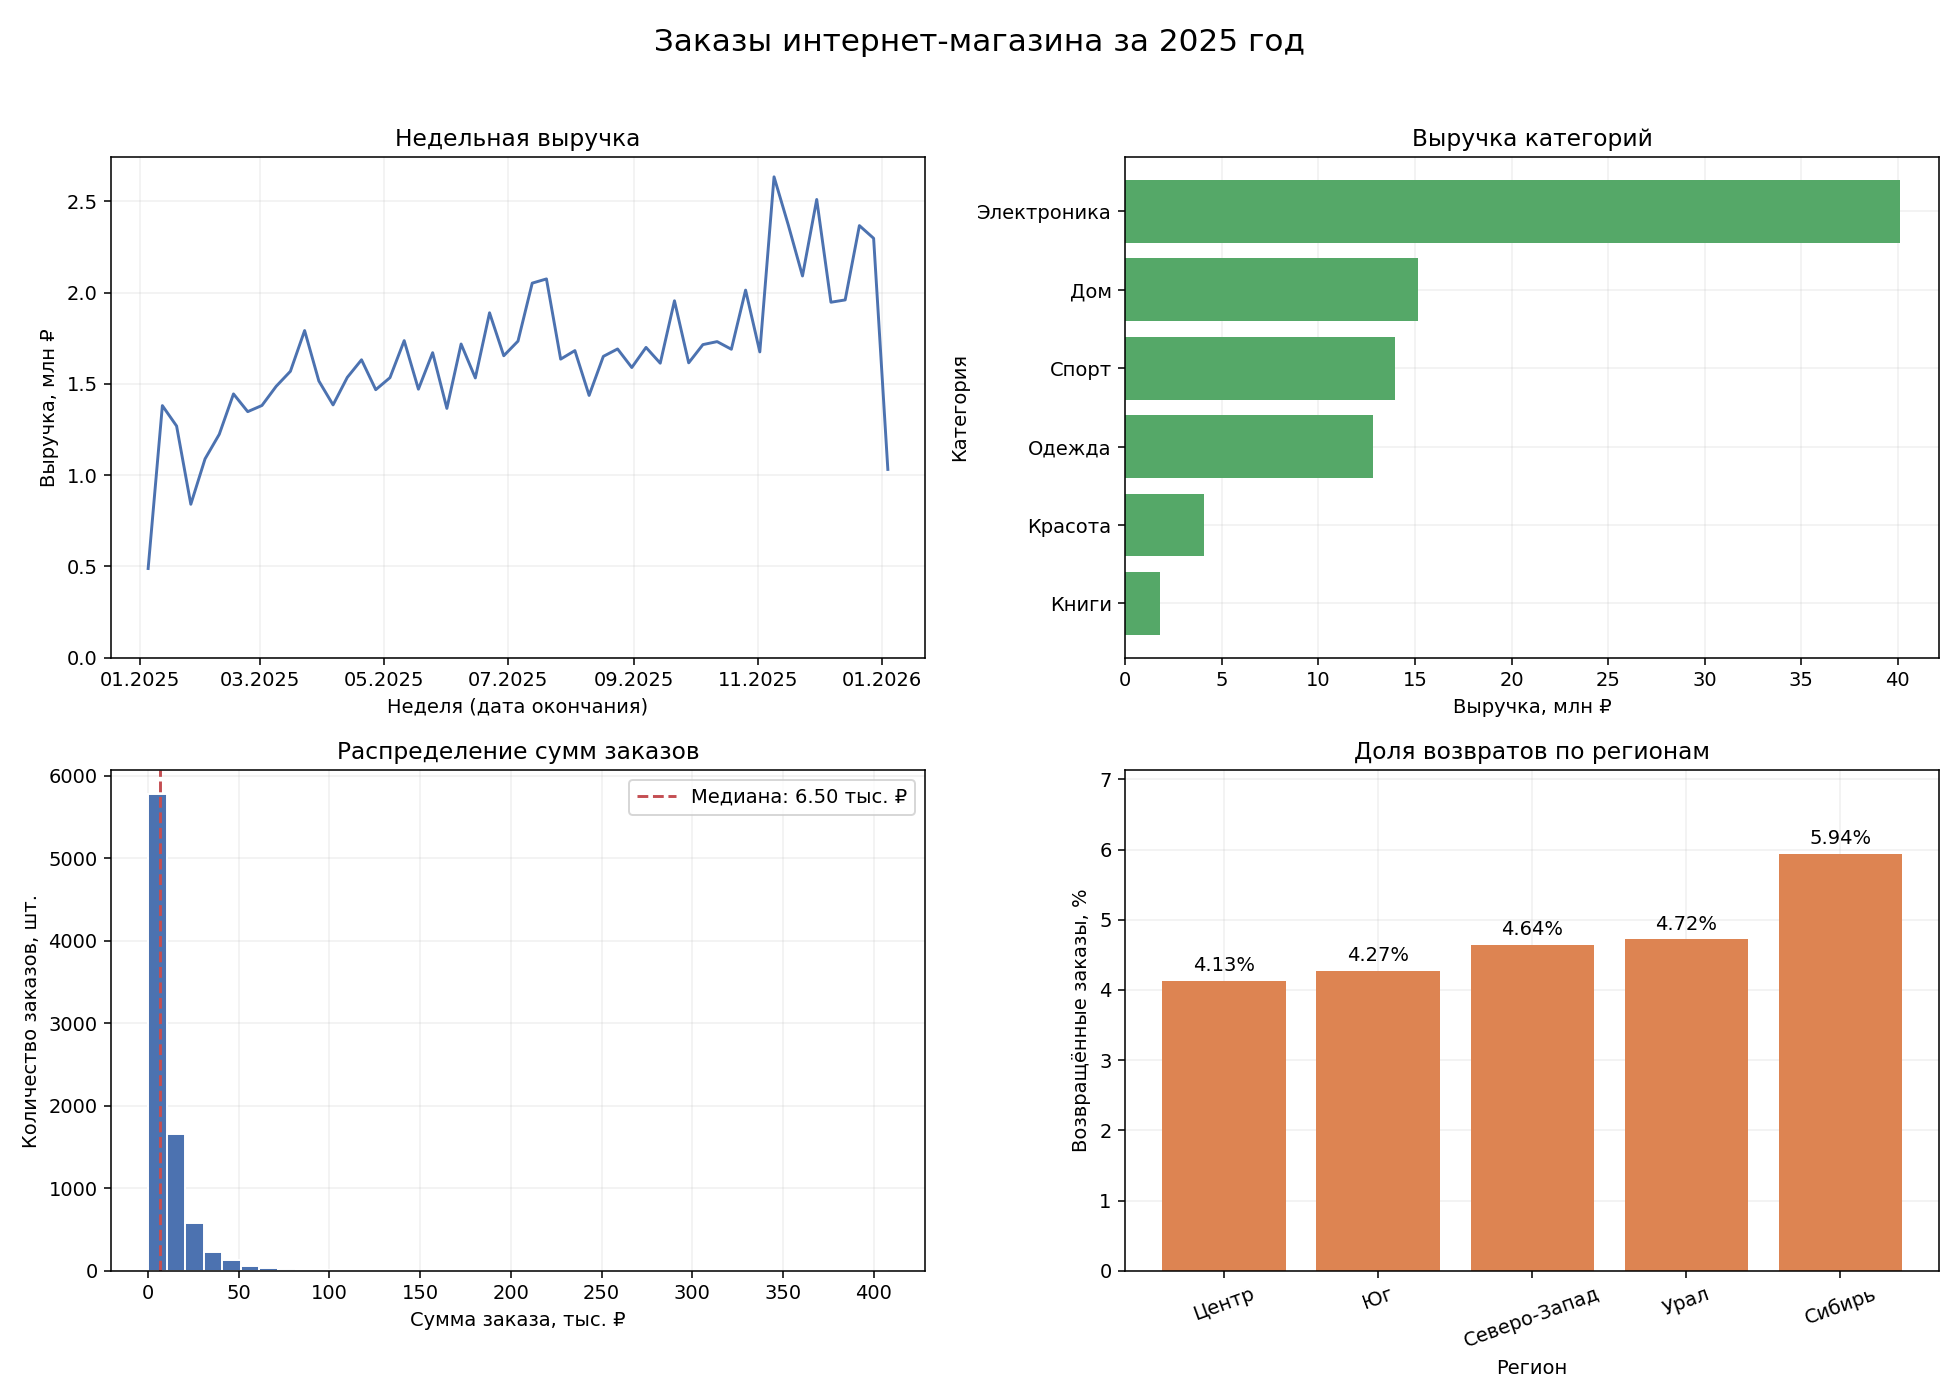

In [11]:
return_share = df.groupby("region")["returned"].mean().sort_values() * 100

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes[0, 0].plot(weekly_revenue.index, weekly_revenue, color="#4C72B0")
axes[0, 0].set_title("Недельная выручка")
axes[0, 0].set_xlabel("Неделя (дата окончания)")
axes[0, 0].set_ylabel("Выручка, млн ₽")
axes[0, 0].set_ylim(bottom=0)
axes[0, 0].xaxis.set_major_locator(mdates.MonthLocator(interval=2))
axes[0, 0].xaxis.set_major_formatter(mdates.DateFormatter("%m.%Y"))

axes[0, 1].barh(category_revenue.index, category_revenue, color="#55A868")
axes[0, 1].set_title("Выручка категорий")
axes[0, 1].set_xlabel("Выручка, млн ₽")
axes[0, 1].set_ylabel("Категория")

checks = df["revenue"] / 1_000
axes[1, 0].hist(checks, bins=40, color="#4C72B0", edgecolor="white")
axes[1, 0].axvline(checks.median(), color="#C44E52", linestyle="--",
                   label=f"Медиана: {checks.median():.2f} тыс. ₽")
axes[1, 0].set_title("Распределение сумм заказов")
axes[1, 0].set_xlabel("Сумма заказа, тыс. ₽")
axes[1, 0].set_ylabel("Количество заказов, шт.")
axes[1, 0].legend()

bars = axes[1, 1].bar(return_share.index, return_share, color="#DD8452")
axes[1, 1].bar_label(bars, fmt="%.2f%%", padding=3)
axes[1, 1].set_title("Доля возвратов по регионам")
axes[1, 1].set_xlabel("Регион")
axes[1, 1].set_ylabel("Возвращённые заказы, %")
axes[1, 1].set_ylim(0, return_share.max() * 1.2)
axes[1, 1].tick_params(axis="x", rotation=20)

fig.suptitle("Заказы интернет-магазина за 2025 год", fontsize=16)
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig("dashboard.png", dpi=160, bbox_inches="tight")
plt.show()


1. Максимум недельной выручки приходится на 3–9 ноября — 2,63 млн ₽.
2. Электроника принесла 40,13 млн ₽, или 45,66% общей выручки;
   распределение чеков имеет длинный правый хвост, медиана — 6496,75 ₽.
3. Доля возвратов максимальна в Сибири — 5,94% (68 из 1145 заказов),
   минимальна в Центре — 4,13% (130 из 3150).

Панель объединяет динамику, сравнение категорий, распределение чеков и доли возвратов.
Ограничение: данные синтетические, а выручка указана до обработки возвратов,
поэтому её нельзя считать чистой выручкой реального магазина.
